**IMPORTING REQ LIBRARIES**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


**READING THE DATASET**

In [2]:
df=pd.read_csv("autoscout24-germany-dataset 5.csv")

**UNDERSTANDING THE DATA**

In [3]:
df.head()


,mileage,make,model,fuel,gear,offerType,price,hp,year
0,235000,BMW,316,Diesel,Manual,Used,6800,116.0,2011
1,92800,Volkswagen,Golf,Gasoline,Manual,Used,6877,122.0,2011
2,149300,SEAT,Exeo,Gasoline,Manual,Used,6900,160.0,2011
3,96200,Renault,Megane,Gasoline,Manual,Used,6950,110.0,2011
4,156000,Peugeot,308,Gasoline,Manual,Used,6950,156.0,2011


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46405 entries, 0 to 46404
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   mileage    46405 non-null  int64  
 1   make       46405 non-null  object 
 2   model      46262 non-null  object 
 3   fuel       46405 non-null  object 
 4   gear       46223 non-null  object 
 5   offerType  46405 non-null  object 
 6   price      46405 non-null  int64  
 7   hp         46376 non-null  float64
 8   year       46405 non-null  int64  
dtypes: float64(1), int64(3), object(5)
memory usage: 3.2+ MB


In [5]:
df.describe()

,mileage,price,hp,year
count,4.640500e+04,4.640500e+04,46376.000000,46405.000000
mean,7.117786e+04,1.657234e+04,132.990987,2016.012951
std,6.262531e+04,1.930470e+04,75.449284,3.155214
min,0.000000e+00,1.100000e+03,1.000000,2011.000000
25%,1.980000e+04,7.490000e+03,86.000000,2013.000000
50%,6.000000e+04,1.099900e+04,116.000000,2016.000000
75%,1.050000e+05,1.949000e+04,150.000000,2019.000000
max,1.111111e+06,1.199900e+06,850.000000,2021.000000


**Checking for null values**

In [6]:
df.isnull().sum()

mileage        0
make           0
model        143
fuel           0
gear         182
offerType      0
price          0
hp            29
year           0
dtype: int64

In [7]:
((df.isnull().mean())*100).round(2)

mileage      0.00
make         0.00
model        0.31
fuel         0.00
gear         0.39
offerType    0.00
price        0.00
hp           0.06
year         0.00
dtype: float64

**Handling the missing values**

In [8]:
df['gear']=df['gear'].fillna(value='Unknown')
df['model']=df['model'].fillna(value='Unknown')
df['hp']=df['hp'].fillna(df['hp'].median())

In [9]:
((df.isnull().mean())*100).round(2)

mileage      0.0
make         0.0
model        0.0
fuel         0.0
gear         0.0
offerType    0.0
price        0.0
hp           0.0
year         0.0
dtype: float64

**INSPECTING TARGET VARIABLES**

In [10]:
df['price'].dtype

dtype('int64')

In [11]:
df.shape

(46405, 9)

In [12]:
df['price'].value_counts()

price
7990      451
6990      434
8990      417
5990      413
9990      403
         ... 
16439       1
2895        1
3895        1
135007      1
88960       1
Name: count, Length: 6668, dtype: int64

**EDA**


In [13]:
df.corr(numeric_only=True)

,mileage,price,hp,year
mileage,1.000000,-0.302788,-0.015079,-0.676131
price,-0.302788,1.000000,0.747530,0.405633
hp,-0.015079,0.747530,1.000000,0.167138
year,-0.676131,0.405633,0.167138,1.000000


<Axes: >

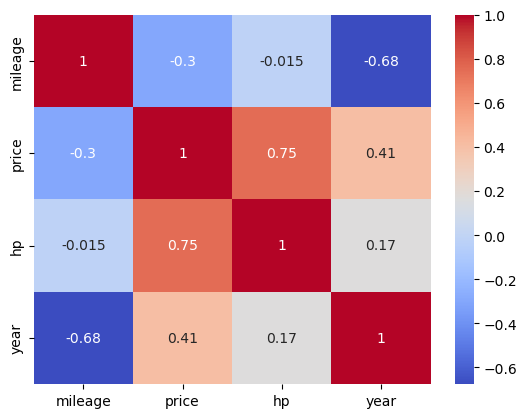

In [14]:
sns.heatmap(df.corr(numeric_only=True),cmap='coolwarm',annot=True)

**DATA VIZ**

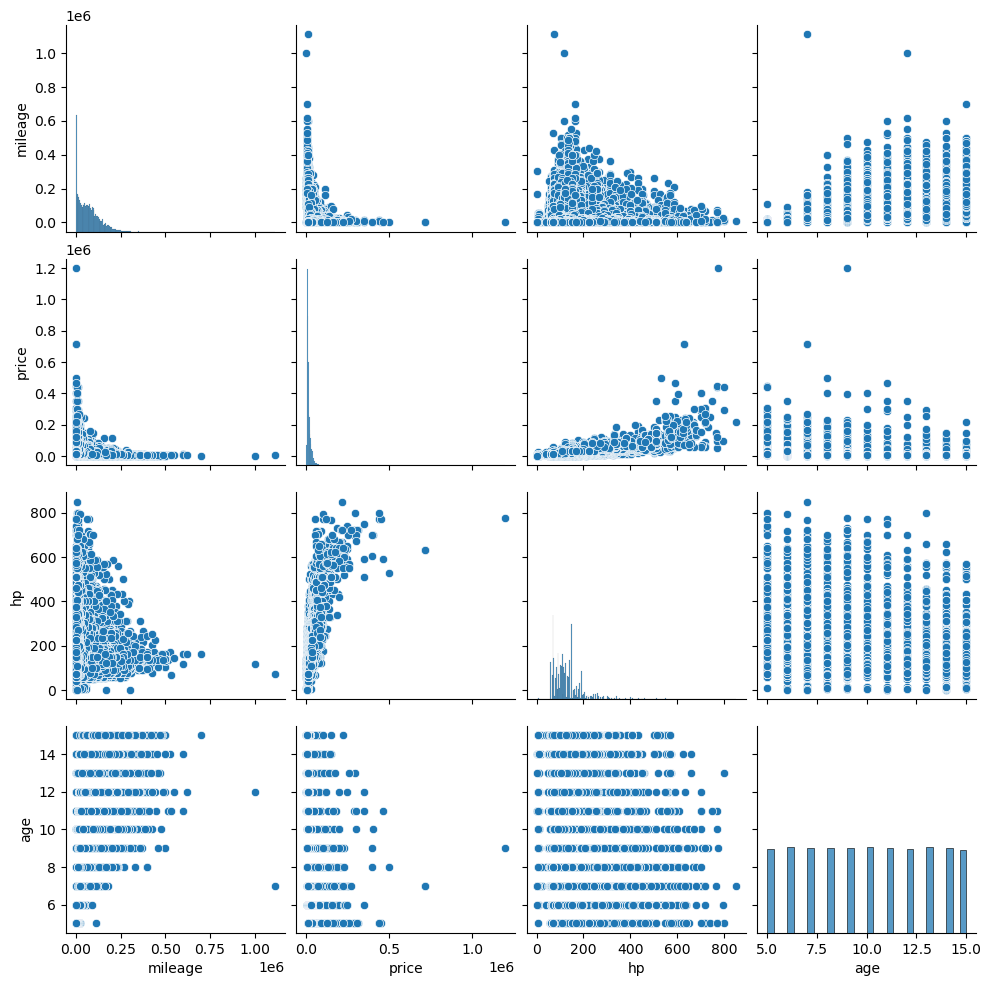

In [59]:
sns.pairplot(df)

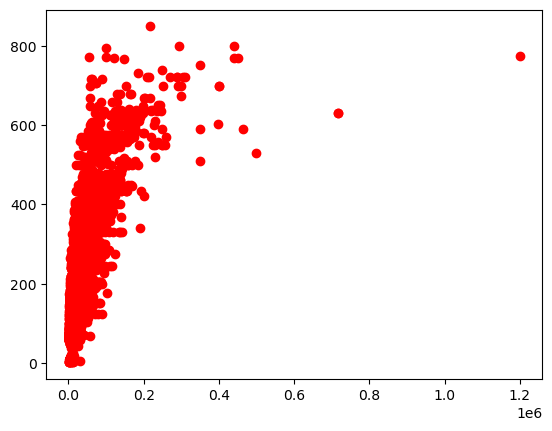

In [92]:
plt.scatter(df['price'],df['hp'],color='red')

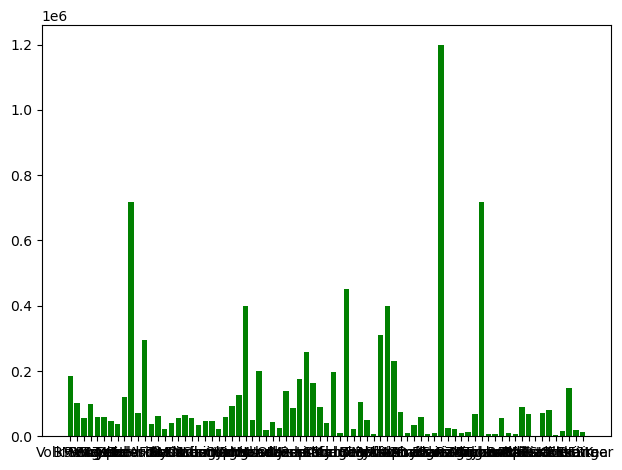

In [102]:
plt.bar(df['make'],df['price'],color='green')

plt.tight_layout()

**INTERPRETATION**

1.)hp and price are positively correlated 
2.)year and mileage are negatively correlated



**FEATURE ENGINEERING**

In [15]:
df['age']=2026-df['year']

In [16]:
df.drop(columns='year',inplace=True)

In [17]:
df.head()

,mileage,make,model,fuel,gear,offerType,price,hp,age
0,235000,BMW,316,Diesel,Manual,Used,6800,116.0,15
1,92800,Volkswagen,Golf,Gasoline,Manual,Used,6877,122.0,15
2,149300,SEAT,Exeo,Gasoline,Manual,Used,6900,160.0,15
3,96200,Renault,Megane,Gasoline,Manual,Used,6950,110.0,15
4,156000,Peugeot,308,Gasoline,Manual,Used,6950,156.0,15


**TRAIN TEST SPLIT**

In [18]:
from sklearn.model_selection import train_test_split

In [19]:
x=df.drop(columns='price')
y=df['price']

In [20]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

In [21]:
x_train.shape

(37124, 8)

In [22]:
x_test.shape

(9281, 8)

In [23]:
y_train.shape

(37124,)

In [24]:
y_test.shape

(9281,)

**Data preprocessing using column transformer**

In [25]:
numeric_features=['mileage','hp','age']
categorical_features=['make','model','fuel','gear','offerType']

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler

In [27]:
numeric_transformer=StandardScaler()
categorical_transformer=OneHotEncoder(handle_unknown='ignore')

In [28]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

**MACHINE LEARNING**

Pipeline Creation


**LINEAR REGRESSION**

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

In [30]:
lr = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regression', LinearRegression())
    ]
)
lr.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [31]:
lr_p= lr.predict(x_test)



In [32]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [33]:
print("MAE:", mean_absolute_error(y_test,lr_p))
print("RMSE:", mean_squared_error(y_test,lr_p) ** 0.5)
print("R² Score:", r2_score(y_test,lr_p))

MAE: 2887.991124035671
RMSE: 7130.86254089647
R² Score: 0.8479277982071413


In [34]:
result={}
result['Linear Regression']={"MAE":mean_absolute_error(y_test,lr_p),
                             "RMSE" :mean_squared_error(y_test,lr_p) ** 0.5,
                             "R² Score": r2_score(y_test,lr_p)}
                             

In [35]:
result

{'Linear Regression': {'MAE': 2887.991124035671,
  'RMSE': 7130.86254089647,
  'R² Score': 0.8479277982071413}}

**DECISION TREE**

In [36]:
from sklearn.tree import DecisionTreeRegressor


In [37]:
dtree = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regression',DecisionTreeRegressor())
    ]
)
dtree.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [38]:
d_p=dtree.predict(x_test)

In [39]:
print("MAE:", mean_absolute_error(y_test,d_p))
print("RMSE:", mean_squared_error(y_test,d_p) ** 0.5)
print("R² Score:", r2_score(y_test,d_p))

MAE: 2316.4505483448206
RMSE: 6817.863476609799
R² Score: 0.8609847947013336


In [40]:
result['Decision Tree Regressor']={"MAE":mean_absolute_error(y_test,d_p),
                             "RMSE" :mean_squared_error(y_test,d_p) ** 0.5,
                             "R² Score": r2_score(y_test,d_p)}

**Random Forest Regressor**

In [41]:
from sklearn.ensemble import RandomForestRegressor

In [42]:
rf = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regression',RandomForestRegressor(n_estimators=5))
    ]
)
rf.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [43]:
rf_p=rf.predict(x_test)

In [44]:
print("MAE:", mean_absolute_error(y_test,rf_p))
print("RMSE:", mean_squared_error(y_test,rf_p) ** 0.5)
print("R² Score:", r2_score(y_test,rf_p))

MAE: 2020.8301300476269
RMSE: 5895.171558369763
R² Score: 0.8960657704907511


In [45]:
result['RandomForestRegressor']={"MAE":mean_absolute_error(y_test,rf_p),
                             "RMSE" :mean_squared_error(y_test,rf_p) ** 0.5,
                             "R² Score": r2_score(y_test,rf_p)}

**FINETUNING USING GRIDSEARCH FOR MORE RELIABLE OUTPUT**

In [46]:
from sklearn.model_selection import GridSearchCV

In [47]:
param_grid = {
    'regression__n_estimators': [10, 50, 100]
}

In [48]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor(random_state=42))
])

grid = GridSearchCV(
    rf_pipeline,
    param_grid=param_grid,
    scoring='r2',
    cv=3,
    verbose=3,
    n_jobs=1
)

In [49]:
grid.fit(x_train,y_train)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
[CV 1/3] END .......regression__n_estimators=10;, score=0.888 total time=   6.4s
[CV 2/3] END .......regression__n_estimators=10;, score=0.766 total time=   6.4s
[CV 3/3] END .......regression__n_estimators=10;, score=0.807 total time=   6.5s
[CV 1/3] END .......regression__n_estimators=50;, score=0.897 total time=  32.0s
[CV 2/3] END .......regression__n_estimators=50;, score=0.763 total time=  32.1s
[CV 3/3] END .......regression__n_estimators=50;, score=0.824 total time=  31.2s
[CV 1/3] END ......regression__n_estimators=100;, score=0.910 total time= 1.1min
[CV 2/3] END ......regression__n_estimators=100;, score=0.764 total time= 1.0min
[CV 3/3] END ......regression__n_estimators=100;, score=0.825 total time= 1.0min


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'regression__n_estimators': [10, 50, ...]}"
,scoring,'r2'
,n_jobs,1
,refit,True
,cv,3
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [50]:
grid.best_params_

{'regression__n_estimators': 100}

**Training the Tuned Model**

In [51]:
rf_tuned = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regression',RandomForestRegressor(n_estimators=100))
    ]
)
rf_tuned.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [52]:
rf_t_pred=rf_tuned.predict(x_test)

In [53]:
print("MAE:", mean_absolute_error(y_test,rf_t_pred))
print("RMSE:", mean_squared_error(y_test,rf_t_pred) ** 0.5)
print("R² Score:", r2_score(y_test,rf_t_pred))

MAE: 1840.953397414509
RMSE: 5554.532367373926
R² Score: 0.9077299601754941


In [54]:
result['RandomForest_Tuned']={"MAE":mean_absolute_error(y_test,rf_t_pred),
                             "RMSE" :mean_squared_error(y_test,rf_t_pred) ** 0.5,
                             "R² Score": r2_score(y_test,rf_t_pred)}

In [55]:
result

{'Linear Regression': {'MAE': 2887.991124035671,
  'RMSE': 7130.86254089647,
  'R² Score': 0.8479277982071413},
 'Decision Tree Regressor': {'MAE': 2316.4505483448206,
  'RMSE': 6817.863476609799,
  'R² Score': 0.8609847947013336},
 'RandomForestRegressor': {'MAE': 2020.8301300476269,
  'RMSE': 5895.171558369763,
  'R² Score': 0.8960657704907511},
 'RandomForest_Tuned': {'MAE': 1840.953397414509,
  'RMSE': 5554.532367373926,
  'R² Score': 0.9077299601754941}}

In [56]:
result_df=pd.DataFrame(result)
result_df

,Linear Regression,Decision Tree Regressor,RandomForestRegressor,RandomForest_Tuned
MAE,2887.991124,2316.450548,2020.830130,1840.953397
RMSE,7130.862541,6817.863477,5895.171558,5554.532367
R² Score,0.847928,0.860985,0.896066,0.907730


**We can clearly see that the tuned Random Forest Model Outperformed the other models**

Hence,we are proceeding with this model to create our Car price predictor


In [57]:
import joblib

In [58]:
joblib.dump(rf_tuned,"CAR_PRICE_PREDICTOR.pkl")

['CAR_PRICE_PREDICTOR.pkl']